# 2.1 BLEU Score — Evaluating Machine Translation

## What is BLEU?

BLEU stands for Bilingual Evaluation Understudy. It measures how closely a machine-generated translation matches one or more human-written reference translations, mainly by comparing overlapping word sequences.

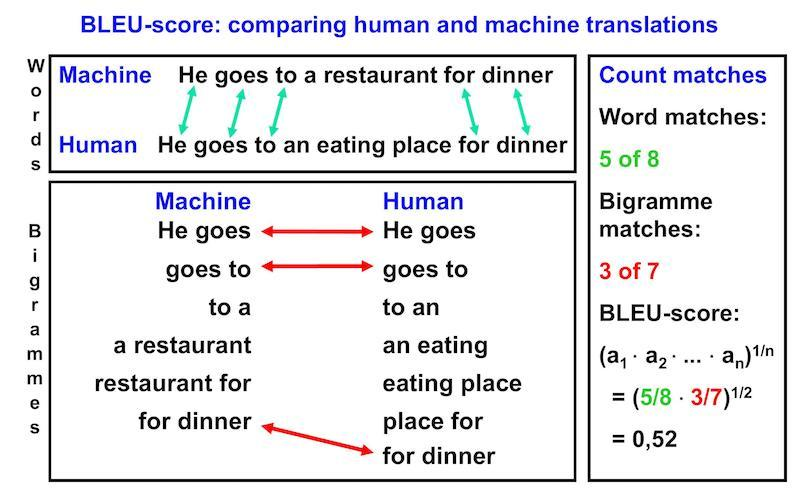

Imagine a translation model translates a French sentence into English.

- Reference: The cat is sitting on the mat.
- Model output: The cat is sitting on the mat.
- Another output: The cat sits on a mat.

The first output matches the reference exactly, so it receives a higher BLEU score under the usual setup. The second shares many words with the reference, but some word sequences differ.

The key idea: BLEU compares the generated translation against a reference; it doesn't directly understand whether the sentence's meaning is correct.

## How does BLEU work?

BLEU mainly combines two ideas.

### 1. N-gram precision

An n-gram is a sequence of \\(n\\) consecutive tokens.

For the sentence “the cat is sitting”:

| N-gram type       | Examples                          |
| ----------------- | --------------------------------- |
| Unigram (1 word)  | `the`, `cat`, `is`, `sitting`     |
| Bigram (2 words)  | `the cat`, `cat is`, `is sitting` |
| Trigram (3 words) | `the cat is`, `cat is sitting`    |

BLEU checks how many of the generated translation's n-grams also occur in the reference.

- Unigram precision: matches individual words.
- Bigram precision: matches pairs of consecutive words.
- Higher-order precision: checks longer word sequences.

This helps BLEU consider word order, not just whether the same words appear.

### 2. Brevity penalty

A model might generate a very short sentence containing only the easiest matching words. BLEU penalizes translations that are too short compared with the reference.

So BLEU combines n-gram precision with a brevity penalty (BP).

## BLEU formula (just understand the idea)

The usual BLEU formula combines modified n-gram precisions with a brevity penalty:

\\[ \mathrm{BLEU}=\mathrm{BP}\times \exp\left(\sum\_{n=1}^{N}w_n\log p_n\right) \\]

- \\(p_n\\): modified precision for n-grams of length \\(n\\).
- \\(w_n\\): weight given to each n-gram length.
- \\(\mathrm{BP}\\): brevity penalty, which reduces the score for overly short translations.

The standard BLEU setup often uses n-grams from 1 to 4. Scores are commonly reported from 0 to 100, although the underlying formula produces a value from 0 to 1. Higher is generally better, but scores should be compared using the same evaluation setup.

### BLEU's limitation

Two translations can express the same meaning using different words, and BLEU may score one lower because its word sequences differ from the reference. Therefore, BLEU is useful for automatic comparison, but it is not a complete measure of translation quality.

# 2.2 Perplexity — Evaluating a Language Model

## What is perplexity?

Perplexity (PPL) measures how well a language model predicts the next token in a sequence.

Imagine the model reads:

> “I drink a cup of \_\_\_”

It might assign these probabilities to the next token:

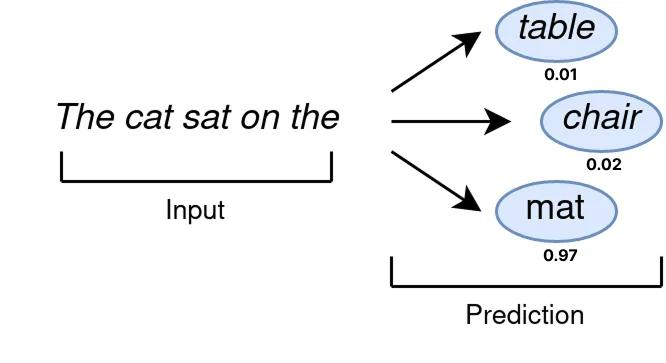

| Possible next token | Model's probability |
| ------------------- | ------------------- |
| tea                 | 0.60                |
| coffee              | 0.25                |
| water               | 0.10                |
| other tokens        | 0.05                |

If the actual next token is `tea`, the model assigned it a high probability. If the actual token is something the model considered very unlikely, the model is more surprised by the data.

Perplexity summarizes this predictive uncertainty across a sequence of tokens.


## How is perplexity calculated?

The formula is:

\\[ \mathrm{PPL}=\exp\left( -\frac{1}{N}\sum\_{t=1}^{N} \log P(x_t\mid x\_{\<t}) \right) \\]

Don't worry about memorizing every symbol yet. The important idea is:

1. The model predicts probabilities for the actual tokens.
2. We calculate how poorly it predicted those tokens on average.
3. We exponentiate that average to obtain perplexity.

### Simple numerical example

Suppose a model predicts each of four actual tokens with probability \\(0.5\\). Its perplexity is:

\\[ \mathrm{PPL}=\exp(-\log 0.5)=2 \\]

If it predicts each actual token with probability \\(0.25\\):

\\[ \mathrm{PPL}=\exp(-\log 0.25)=4 \\]

Model A

## PPL = 2

Higher probability on actual tokens

Better prediction

Model B

## PPL = 4

Lower probability on actual tokens

More uncertainty

Lower perplexity is generally better when evaluating models on the same test data with comparable tokenization and evaluation settings.

However, low perplexity does not guarantee that a model generates accurate, helpful or grammatically perfect text. Also, perplexity is primarily defined for autoregressive language models; it is not directly applicable in the same way to masked language models such as standard BERT.



## BLEU vs. Perplexity — Final distinction

|                  | BLEU                                                      | Perplexity                                         |
| ---------------- | --------------------------------------------------------- | -------------------------------------------------- |
| Evaluates        | Generated translation against references                  | Predictions of actual tokens                       |
| Main question    | Does the translation overlap with reference translations? | How well does the model predict the observed text? |
| Better direction | Higher                                                    | Lower                                              |
| Common use       | Machine translation                                       | Language modeling                                  |

## What you should remember 🧠

- BLEU: compares machine translations with human reference translations using n-gram overlap and a brevity penalty.
- Perplexity: measures a language model's predictive uncertainty over observed tokens.
- BLEU higher is generally better; perplexity lower is generally better.
- Neither metric alone guarantees that generated text is meaningful or correct.

---